In [ ]:
# 붓꽃 분류: DecisionTreeClassifier()는 분류 모델을 만듭니다.
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")

df_clf = DecisionTreeClassifier(random_state= 42)
iris_df = load_iris()
X_train,X_test,y_train,y_test = train_test_split(iris_df.data, iris_df.target, test_size = 0.2 , random_state= 42)

df_clf.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
from sklearn.tree import export_graphviz

# export_graphviz()는 트리 구조를 Graphviz DOT 형식으로 저장합니다.
export_graphviz(df_clf, out_file="tree.dot", class_names = iris_df.target_names,
                feature_names= iris_df.feature_names, impurity=True , filled=True)

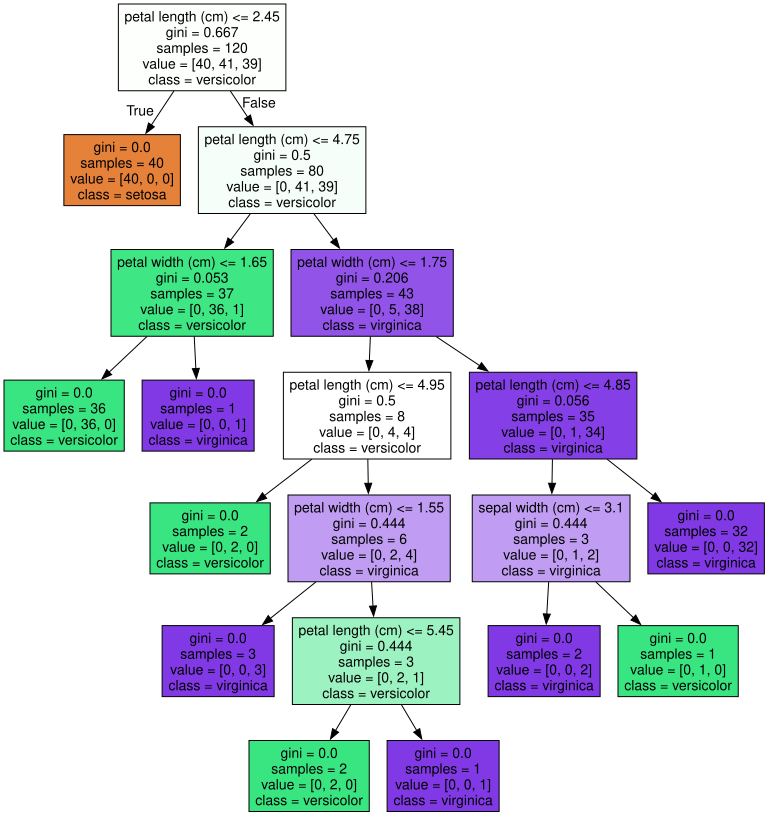

In [ ]:
# open()은 파일을 열고, read()는 내용을 읽습니다. with 블록 종료 시 파일이 닫힙니다.

import graphviz

with open('tree.dot', encoding='utf-8') as f:
    dot_graph = f.read()

# graphviz.Source()는 DOT 문자열을 그림 객체로 만듭니다.
graphviz.Source(dot_graph)

Feature Important : [0.    0.017 0.906 0.077]
sepal length (cm) 0.0
sepal width (cm) 0.016670139612419255
petal length (cm) 0.9061433868879218
petal width (cm) 0.07718647349965893


<Axes: >

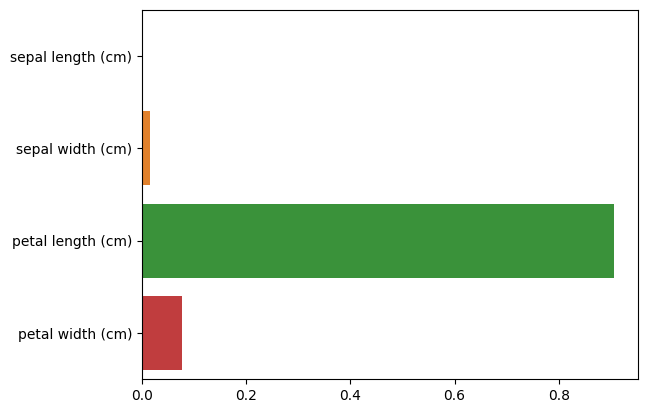

In [ ]:

import seaborn as sns
import numpy as np

# np.round()는 반올림, zip()은 같은 순서끼리 묶기, print()는 출력입니다.
print("Feature Important :", np.round(df_clf.feature_importances_,3))

for name, value in zip (iris_df.feature_names,df_clf.feature_importances_):
    print(name,value)

# sns.barplot()은 막대그래프를 그립니다.
sns.barplot(x = df_clf.feature_importances_ , y = iris_df.feature_names)

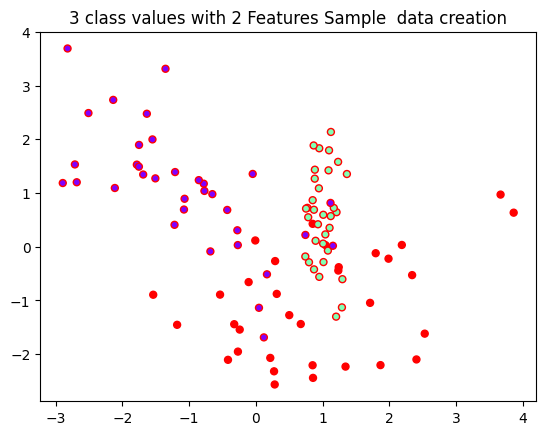

In [ ]:

from sklearn.datasets import make_classification
import matplotlib.pyplot as plt

plt.title("3 class values with 2 Features Sample  data creation")

# make_classification()은 분류 연습용 가상 데이터를 만듭니다.
X_features, y_labels = make_classification(n_features=2 , n_redundant= 0, n_informative= 2 , n_classes = 3, n_clusters_per_class =1, random_state = 0)

# plt.scatter()는 데이터를 점으로 그리며 c는 정답별 색상입니다.
plt.scatter(X_features[: , 0], X_features[:,1], marker= "o", c= y_labels, s = 25 , cmap= "rainbow", edgecolors="red")

In [ ]:
# 이 함수는 두 특성 공간에서 데이터와 분류 영역을 그립니다.


import numpy as np
import matplotlib.pyplot as plt

def visualize_boundary(model, X, y):
    fig, ax = plt.subplots() # plt.subplots()는 그림과 축을 만듭니다. ax.scatter()는 점을 그립니다.
    ax.scatter(
        X[:, 0], X[:, 1], c=y, s=25, cmap="rainbow",
        edgecolors="k", vmin=y.min(), vmax=y.max(), zorder=3
    )

# min()/max()는 최소/최대값, set_xlim()/set_ylim()은 축 범위를 정합니다. axis("off")는 축을 숨깁니다.
    ax.set_xlim(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5)
    ax.set_ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
    ax.axis("off")

# model.fit()은 학습합니다. np.linspace()는 균일한 좌표를 만들고 get_xlim()/get_ylim()은 축 범위를 읽습니다.
    model.fit(X, y)
# np.meshgrid()는 좌표 격자
    xx, yy = np.meshgrid(
        np.linspace(*ax.get_xlim(), num=200),
        np.linspace(*ax.get_ylim(), num=200)
    )
# model.predict()는 각 점을 예측합니다. reshape()는 배열 모양을 바꿉니다. np.c_는 열 연결, ravel()은 일렬 배열을 만듭니다.
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    n_classes = len(np.unique(y))
# np.unique()는 중복 없는 정답을 구하고 len()은 개수를 셋니다. np.arange()는 일정 간격 수를 만듭니다.
# ax.contourf()는 분류 영역을 색칠하고 return은 축 객체를 반환합니다.
    ax.contourf(
        xx, yy, Z, alpha=0.3,
        levels=np.arange(n_classes + 1) - 0.5,
        cmap="rainbow", vmin=y.min(), vmax=y.max(), zorder=1
    )
    return ax

<Axes: >

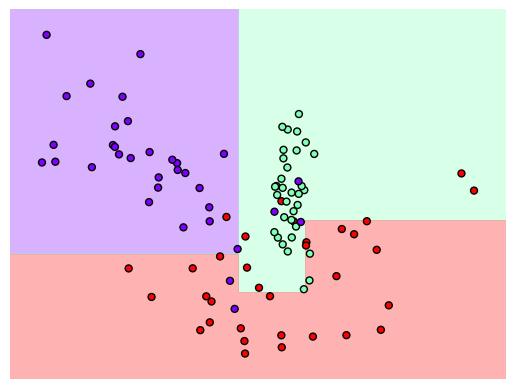

In [7]:
# DecisionTreeClassifier()는 분류 트리입니다. min_samples_leaf는 잎 노드의 최소 표본 수입니다.
# fit()은 학습하고 visualize_boundary()는 앞서 정의한 시각화 함수입니다.

dt_clf = DecisionTreeClassifier(min_samples_leaf=6 , random_state= 156).fit(X_features, y_labels)

visualize_boundary(dt_clf , X_features, y_labels)

In [ ]:
# open()은 UTF-8로 파일을 읽고 csv.reader()는 CSV 행을 읽습니다. next()는 헤더 한 줄을 가져옵니다.
# range()는 순번 범위, len()은 개수, pd.DataFrame()은 표를 만듭니다.

import csv
import pandas as pd
import matplotlib.pyplot as plt

with open('./human_activity_train.csv', encoding = 'utf-8') as f:
    header = next(csv.reader(f))

feature_name_org = header[:-2]

feature_name_df = pd.DataFrame({'column_index': range(1, len(feature_name_org) + 1),
                                'column_name': feature_name_org})


# iloc[:,1]은 두 번째 열을 선택합니다. values는 배열, tolist()는 리스트로 바꿑니다. print()는 출력합니다.
feature_name = feature_name_df.iloc[:, 1].values.tolist()  # 칼럼 이름 중복 확인
print(len(feature_name))
print(feature_name[:10])

561
['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z', 'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z', 'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z', 'tBodyAcc-max()-X']


In [9]:
# pd.read_csv()는 CSV를 표로 읽습니다. df.head()는 앞 5행을 보여줍니다.

df = pd.read_csv ("./human_activity_test.csv")
df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.257178,-0.023285,-0.014654,-0.938404,-0.920091,-0.667683,-0.952501,-0.925249,-0.674302,-0.894088,...,-0.705974,0.006462,0.162920,-0.825886,0.271151,-0.720009,0.276801,-0.057978,2,STANDING
1,0.286027,-0.013163,-0.119083,-0.975415,-0.967458,-0.944958,-0.986799,-0.968401,-0.945823,-0.894088,...,-0.594944,-0.083495,0.017500,-0.434375,0.920593,-0.698091,0.281343,-0.083898,2,STANDING
2,0.275485,-0.026050,-0.118152,-0.993819,-0.969926,-0.962748,-0.994403,-0.970735,-0.963483,-0.939260,...,-0.640736,-0.034956,0.202302,0.064103,0.145068,-0.702771,0.280083,-0.079346,2,STANDING
3,0.270298,-0.032614,-0.117520,-0.994743,-0.973268,-0.967091,-0.995274,-0.974471,-0.968897,-0.938610,...,-0.736124,-0.017067,0.154438,0.340134,0.296407,-0.698954,0.284114,-0.077108,2,STANDING
4,0.274833,-0.027848,-0.129527,-0.993852,-0.967445,-0.978295,-0.994111,-0.965953,-0.977346,-0.938610,...,-0.846595,-0.002223,-0.040046,0.736715,-0.118545,-0.692245,0.290722,-0.073857,2,STANDING


In [10]:
# df.info()는 행/열 수, 자료형, 값 개수 등 표의 요약을 표시합니다.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2947 entries, 0 to 2946
Columns: 563 entries, tBodyAcc-mean()-X to Activity
dtypes: float64(561), int64(1), object(1)
memory usage: 12.7+ MB


In [11]:
# groupby()는 같은 이름을 묶고 count()는 개수를 셋니다. >1은 중복 이름만 고릅니다.
# print()는 출력하고 head()는 앞부분을 보여줍니다.

feature_dup_df = feature_name_df.groupby("column_name").count()
print(feature_dup_df[feature_dup_df['column_index']>1].count())
feature_dup_df[feature_dup_df["column_index"]>1].head()

column_index    42
dtype: int64


,column_index
column_name,
"fBodyAcc-bandsEnergy()-1,16",3
"fBodyAcc-bandsEnergy()-1,24",3
"fBodyAcc-bandsEnergy()-1,8",3
"fBodyAcc-bandsEnergy()-17,24",3
"fBodyAcc-bandsEnergy()-17,32",3


In [ ]:
# cumcount()는 그룹 안에서 0부터 순번을 매깁니다. DataFrame()은 표를 만듭니다.

# str()은 숫자를 문자로, drop()은 지정 열을 삭제합니다. return은 결과를 돌려줍니다.

def get_new_feature_name_df(old_feature_name_df):
    feature_dup_df = pd.DataFrame(data = old_feature_name_df.groupby('column_name').cumcount(),
                                  columns = ['dup_cnt'])
    feature_dup_df = feature_dup_df.reset_index() # reset_index()는 인덱스를 열로 옮기고 merge()는 표를 합칩니다.
    new_feature_name_df = pd.merge(old_feature_name_df.reset_index(), feature_dup_df, how = 'outer')

# apply()는 함수를 적용합니다. axis=1은 행 단위입니다. lambda는 짧은 익명 함수입니다.
    new_feature_name_df['column_name'] = new_feature_name_df[['column_name', 'dup_cnt']].apply(lambda x: x[0] + '_' + str(x[1]) if x[1] > 0 else x[0], axis = 1)
    new_feature_name_df = new_feature_name_df.drop(['index'], axis = 1)
    return new_feature_name_df

In [ ]:
# DataFrame()은 표를 만들고 get_new_feature_name_df()는 중복 특성명을 고칩니다.앞서 만든 함수


import csv
import pandas as pd

# ACTION_MAP은 활동명과 숫자 정답의 대응 사전입니다.
ACTION_MAP = {
    "WALKING": 1,
    "WALKING_UPSTAIRS": 2,
    "WALKING_DOWNSTAIRS": 3,
    "SITTING": 4,
    "STANDING": 5,
    "LAYING": 6,
}

# get_human_dataset()은 데이터 준비 함수입니다. open()/csv.reader()/next()로 CSV 헤더를 읽습니다.
def get_human_dataset():
    train_file = "./human_activity_train.csv"
    test_file = "./human_activity_test.csv"

    with open('./human_activity_train.csv', encoding = 'utf-8') as f:
        header = next(csv.reader(f))
    feature_name_org = header[:-2]

    feature_name_df = pd.DataFrame({
        "column_index": range(1, len(feature_name_org) + 1),
        "column_name": feature_name_org
    })

    new_feature_name_df = get_new_feature_name_df(feature_name_df)
    feature_name = new_feature_name_df["column_name"].tolist()

    col_names = feature_name + ["subject", "action"]

# train_df[feature_name]은 특성 열, train_df[["action"]]은 정답 열을 고릅니다. return은 네 데이터를 반환합니다.
    train_df = pd.read_csv(train_file, header=0, names=col_names)
    test_df = pd.read_csv(test_file, header=0, names=col_names)
    X_train = train_df[feature_name]
    X_test = test_df[feature_name]
    y_train = train_df[["action"]]
    y_test = test_df[["action"]]

    return X_train, X_test, y_train, y_test

In [14]:
# get_human_dataset()은 앞서 정의한 데이터 준비 함수입니다. shape는 (행 수, 열 수)이고 print()는 출력합니다.

X_train,X_test,y_train,y_test = get_human_dataset()
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(7352, 561)
(2947, 561)
(7352, 1)
(2947, 1)


In [ ]:
# DecisionTreeClassifier()는 트리 분류기입니다. fit()은 학습, predict()는 예측입니다.

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
df_clf = DecisionTreeClassifier(random_state= 156)
df_clf.fit(X_train, y_train)
pred = df_clf.predict(X_test)
# accuracy_score()는 맞은 예측의 비율을 계산합니다. print()는 출력하고 get_params()는 설정값을 읽습니다.
accuracy = accuracy_score(y_test,pred)
print(accuracy)
print(dt_clf.get_params())

0.8547675602307431
{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 6, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'random_state': 156, 'splitter': 'best'}


In [ ]:

# GridSearchCV()는 설정 후보를 교차 검증합니다. cv=5는 5분할, scoring은 평가 기준입니다.
from sklearn.model_selection import GridSearchCV

params = {"max_depth" : [6,8,10,12,16,20,24]}

grid_cv = GridSearchCV(df_clf, param_grid= params, scoring= "accuracy", cv = 5 , verbose = 1)

# fit()은 탐색을 실행합니다. best_score_는 최고 점수, best_params_는 그 설정입니다.
grid_cv.fit(X_train,y_train)

print(grid_cv.best_score_)
print(grid_cv.best_params_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
0.8513444970102249
{'max_depth': 16}


In [17]:
# pd.DataFrame()은 결과를 표로 만듭니다. cv_results_는 설정별 탐색 결과입니다.
# 대괄호 안 열 이름으로 표시할 열을 고릅니다.

cv_result_df = pd.DataFrame(grid_cv.cv_results_)
cv_result_df[["param_max_depth","mean_test_score"]]

,param_max_depth,mean_test_score
0,6,0.850791
1,8,0.851069
2,10,0.851209
3,12,0.843999
4,16,0.851344
5,20,0.850800
6,24,0.849440


In [18]:
# GridSearchCV()는 설정 조합을 교차 검증합니다. fit()이 탐색을 실행합니다.
# best_score_와 best_params_는 최고 점수와 설정입니다.

params = {
    "max_depth" : [8,12,16,20],
    "min_samples_split": [16,14],
}


grid_cv = GridSearchCV(df_clf, param_grid= params, scoring= "accuracy", cv = 5 , verbose = 1)

grid_cv.fit(X_train,y_train)

print(grid_cv.best_score_)
print(grid_cv.best_params_)


Fitting 5 folds for each of 8 candidates, totalling 40 fits
0.8552873005082386
{'max_depth': 8, 'min_samples_split': 14}


In [ ]:
# best_estimator_는 선택된 모델입니다. predict()는 테스트 특성의 정답을 예측합니다.

best_dt_clf = grid_cv.best_estimator_
pred1 = best_dt_clf.predict(X_test)
# accuracy_score()는 정답 일치 비율을 계산하고 print()는 출력합니다.
accuracy = accuracy_score(y_test, pred1)
print(accuracy)

0.8724126230064473


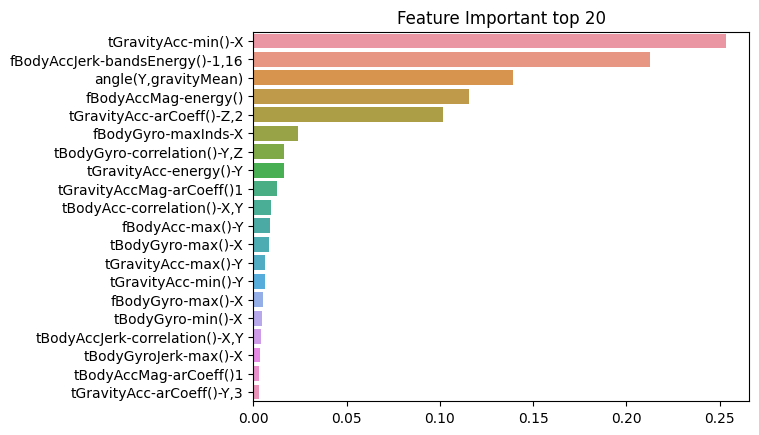

In [ ]:

import seaborn as sns
ftr_importances_values = best_dt_clf.feature_importances_ # feature_importances_는 특성별 중요도입니다. pd.Series()는 이름과 값을 연결합니다.
ftr_importances = pd.Series(ftr_importances_values, index = X_train.columns)
# sort_values()는 정렬하고 ascending=False는 내림차순입니다. [:20]은 상위 20개입니다.
ftr_top20 = ftr_importances.sort_values(ascending = False)[:20]

# plt.Figure()는 그림 크기, plt.title()은 제목, sns.barplot()은 막대그래프, plt.show()는 표시입니다.
plt.Figure(figsize=(8,6)) 
plt.title("Feature Important top 20")
sns.barplot(x = ftr_top20, y= ftr_top20.index)
plt.show()